# Vegetation and water are proxies

**Objective:** Calculate NDVI and a green–NIR NDWI after scaling, and separate spectral patterns from ecological or health outcomes.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

NDVI = (NIR − red)/(NIR + red) describes a spectral contrast often used to study vegetation. Here NDWI = (green − NIR)/(green + NIR); this definition must be stated because other indices also use the name NDWI. Neither ratio measures pathogen concentration, water safety, crop yield or animal health.

We retain a null when a ratio denominator is zero. Very small or negative reflectance can produce ratios outside familiar bounds; the arithmetic and masks should be inspected rather than silently clipping exported values.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=04_vegetation_water.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
for r in data:
    if r["ndvi"] is not None:
        calculated = (r["nir08"] - r["red"]) / (r["nir08"] + r["red"])
        assert abs(calculated - r["ndvi"]) < 1e-5
print("Median NDVI:", round(statistics.median(values("ndvi")), 4))
print("Median green–NIR NDWI:", round(statistics.median(values("ndwi")), 4))

Median NDVI: 0.285
Median green–NIR NDWI: -0.3732


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

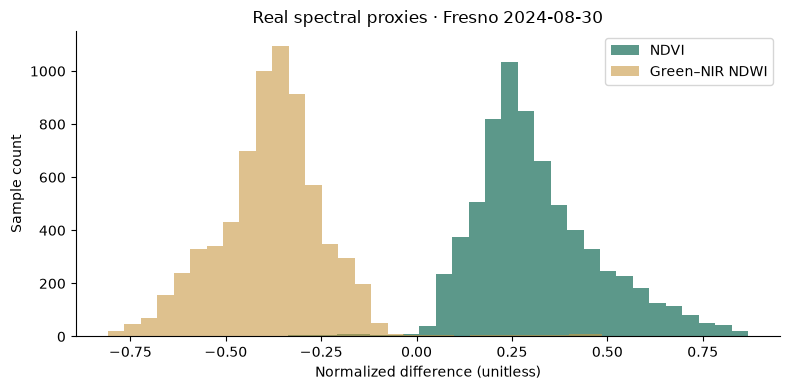

In [3]:
plt.hist(values("ndvi"), bins=30, alpha=.7, label="NDVI", color="#176c59")
plt.hist(values("ndwi"), bins=30, alpha=.6, label="Green–NIR NDWI", color="#c89943")
plt.xlabel("Normalized difference (unitless)"); plt.ylabel("Sample count")
plt.title("Real spectral proxies · Fresno 2024-08-30"); plt.legend()
plt.tight_layout(); plt.show()

## Interpret and extend

Select high and low NDVI samples and inspect their positions. Propose two land-cover explanations and one field observation that could distinguish them. Do not assign a disease or crop condition from the index alone.

## Sources and attribution

- [USGS, Landsat Normalized Difference Vegetation Index](https://www.usgs.gov/landsat-missions/landsat-normalized-difference-vegetation-index).
- [NOAA National Ocean Service, Are all algal blooms harmful?](https://oceanservice.noaa.gov/facts/habharm.html).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.